
# ROLL NUMBER: M26AI1023

**Name:** Anurag Mor

# Foundations of Vision and Language — Individual Mini CV Project (20 Marks)

# 10 Marks for coding and 10 marks for analysis

## Effect of Blur and Sharpening on Object Detection

- **Dataset:** COCO128
- **Model:** Pretrained YOLO11n
- **Platform:** Google Colab
- **Training:** Not required

### What this notebook provides
- package installation,
- COCO128 download,
- pretrained YOLO11n loading,
- dataset paths.

### What you must do
1. **Stage 1 — Baseline:** evaluate YOLO11n on the original COCO128 images.
2. **Stage 2 — Blur:** create a Gaussian-blurred version of the same images and evaluate again.
3. **Stage 3 — Sharpening:** sharpen the blurred images and evaluate again.
4. **Stage 4 — Analysis:** compare the three stages.

The experimental code for Stages 1–3 is intentionally left for you to complete.


## Setup 1 — Install Packages

In [1]:
!pip -q install -U ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.8 MB/s eta 0:00:00


## Setup 2 — Download COCO128

In [2]:
from pathlib import Path
import urllib.request
import zipfile
import os

# Google Colab → /content/datasets
# Local/Jupyter/GPU server → ~/fvl_datasets
if Path("/content").exists() and os.access("/content", os.W_OK):
    DATA_ROOT = Path("/content/datasets")
else:
    DATA_ROOT = Path.home() / "fvl_datasets"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

zip_path = DATA_ROOT / "coco128.zip"
dataset_dir = DATA_ROOT / "coco128"

if not dataset_dir.exists():
    url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"

    print("Downloading COCO128 to:", zip_path)
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_ROOT)

    print("Download and extraction complete.")
else:
    print("COCO128 already exists.")

print("Dataset ready at:", dataset_dir)
print("Images:", dataset_dir / "images" / "train2017")
print("Labels:", dataset_dir / "labels" / "train2017")

Download and extraction complete.
Dataset ready at: /content/datasets/coco128
Images: /content/datasets/coco128/images/train2017
Labels: /content/datasets/coco128/labels/train2017


## Setup 3 — Load Pretrained YOLO11n

In [3]:
PROJECT_ROOT = Path('/fvl_project')
from pathlib import Path
import os

if Path("/content").exists() and os.access("/content", os.W_OK):
    PROJECT_ROOT = Path("/content/fvl_project")
else:
    PROJECT_ROOT = Path.home() / "fvl_project"

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)


Project folder: /content/fvl_project



# Stage 1 — Baseline on Original Images

### Your task
1. Prepare a dataset YAML that points to the original COCO128 images and labels.
2. Run `model.val(...)` using the pretrained YOLO11n model.
3. Record only these four metrics:
   - Precision
   - Recall
   - mAP@0.5
   - mAP@0.5:0.95
4. Save at least **3 prediction examples**.


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 648.1±267.8 MB/s, size: 46.2 KB)
val: Scanning /content/datasets/coco128/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 974.6it/s 0.1s
val: New cache created: /content/datasets/coco128/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.2s/it 25.8s
                   all        128        929      0.663      0.589       0.67      0.502
Speed: 5.2ms preprocess, 186.

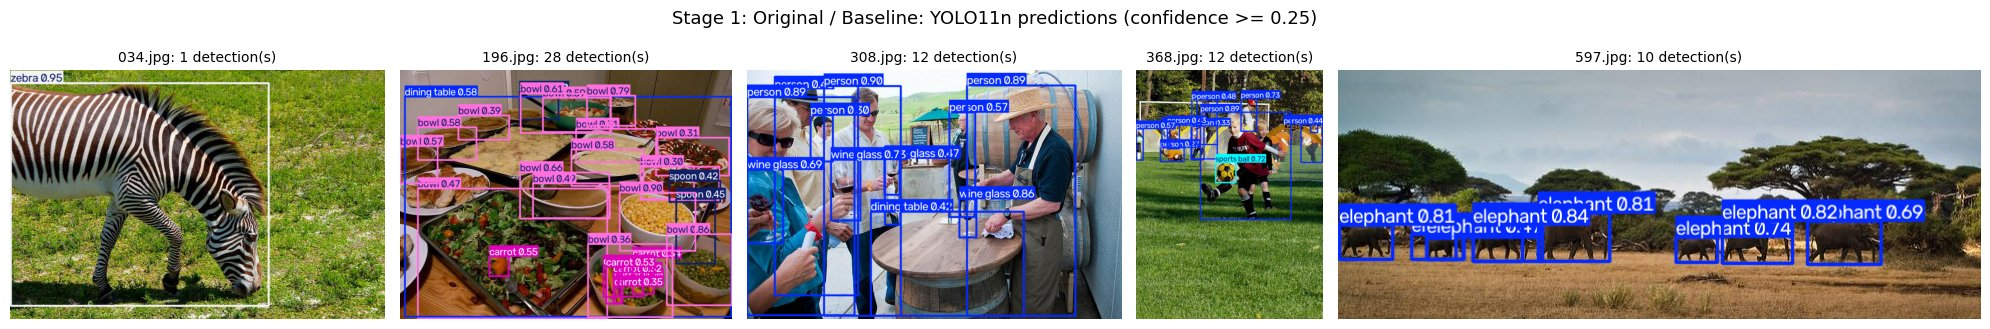

000000000034.jpg: 1 detection(s): 1 zebra [best 0.95]
000000000196.jpg: 28 detection(s): 17 bowl [best 0.90], 7 carrot [best 0.55], 3 spoon [best 0.45], 1 dining table [best 0.58]
000000000308.jpg: 12 detection(s): 6 person [best 0.90], 5 wine glass [best 0.86], 1 dining table [best 0.42]
000000000368.jpg: 12 detection(s): 11 person [best 0.89], 1 sports ball [best 0.72]
000000000597.jpg: 10 detection(s): 10 elephant [best 0.84]
Annotated images saved in: /content/fvl_project/runs/stage1_original_predictions


In [4]:

# STAGE 1 — STUDENT CODE

import yaml
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from ultralytics import YOLO

try:                                           # store the inline figures as JPEG so the saved notebook stays small
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg', pil_kwargs={'quality': 85})
except ImportError:
    pass

ROLL = 'M26AI1023'

# Pretrained YOLO11n (COCO weights). This one model object is used in all three stages; it is never trained.
model = YOLO('yolo11n.pt')

# The evaluation settings are fixed here and reused in every stage,
# so the only thing that changes from stage to stage is the images.
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
VAL_ARGS = dict(imgsz=640, batch=16, conf=0.001, iou=0.7, device=DEVICE,
                workers=0, plots=False, verbose=False)        # Ultralytics validation defaults
PRED_CONF = 0.25              # confidence threshold used for the prediction examples
SPLIT = 'train2017'           # COCO128 has one split; it is used as the validation set

RUNS_DIR = PROJECT_ROOT / 'runs'
FIG_DIR = PROJECT_ROOT / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# The same five images are shown in every stage so that the stages can be compared directly:
# 034 has one large object, 196 is the most crowded image of COCO128 (42 labelled objects),
# and 308, 368, 597 contain several medium and small objects.
EXAMPLE_IMAGES = ['000000000034.jpg', '000000000196.jpg', '000000000308.jpg',
                  '000000000368.jpg', '000000000597.jpg']

final_results = {}            # stage name -> the four required metrics
example_log = {}              # stage name -> detections found in each example image


def make_yaml(root, tag):
    """Write a dataset YAML for a COCO128-style folder (images/train2017 + labels/train2017)."""
    cfg = {'path': str(root), 'train': f'images/{SPLIT}', 'val': f'images/{SPLIT}', 'names': model.names}
    yaml_path = PROJECT_ROOT / f'{tag}.yaml'
    with open(yaml_path, 'w') as f:
        yaml.safe_dump(cfg, f, sort_keys=False)
    return yaml_path


def evaluate(root, tag):
    """Run model.val(...) on the dataset stored under `root` and return the four required metrics."""
    res = model.val(data=str(make_yaml(root, tag)), project=str(RUNS_DIR), name=f'{tag}_val',
                    exist_ok=True, **VAL_ARGS)
    return {'Precision': float(res.box.mp), 'Recall': float(res.box.mr),
            'mAP@0.5': float(res.box.map50), 'mAP@0.5:0.95': float(res.box.map)}


def report(stage, metrics):
    final_results[stage] = metrics
    print(f'\n{stage}')
    for k, v in metrics.items():
        print(f'  {k:<13}: {v:.4f}')


def predict_examples(root, tag, stage):
    """Run model.predict(...) on the example images, save the annotated images and show them."""
    sources = [str(root / 'images' / SPLIT / name) for name in EXAMPLE_IMAGES]
    preds = model.predict(source=sources, conf=PRED_CONF, imgsz=640, device=DEVICE, save=True,
                          project=str(RUNS_DIR), name=f'{tag}_predictions', exist_ok=True, verbose=False)
    example_log[stage] = {}
    ratios = [r.orig_shape[1] / r.orig_shape[0] for r in preds]            # width / height of each image
    fig, axes = plt.subplots(1, len(preds), figsize=(20, 20 / sum(ratios) + 0.9),
                             gridspec_kw={'width_ratios': ratios})
    for ax, name, r in zip(axes, EXAMPLE_IMAGES, preds):
        example_log[stage][name] = [(model.names[int(c)], float(p)) for c, p in zip(r.boxes.cls, r.boxes.conf)]
        ax.imshow(r.plot()[..., ::-1])                         # BGR -> RGB for display
        ax.set_title(f'{name[-7:]}: {len(r.boxes)} detection(s)', fontsize=10)
        ax.axis('off')
    fig.suptitle(f'{stage}: YOLO11n predictions (confidence >= {PRED_CONF})', fontsize=13)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{ROLL}_{tag}_predictions.png', dpi=120, bbox_inches='tight')
    plt.show()
    for name, dets in example_log[stage].items():                # text summary: number of boxes and best confidence per class
        counts = Counter(c for c, _ in dets)
        listing = ', '.join(f'{n} {c} [best {max(p for k, p in dets if k == c):.2f}]' for c, n in counts.most_common())
        print(f'{name}: {len(dets)} detection(s): {listing}')
    print('Annotated images saved in:', preds[0].save_dir)


# 1. Dataset YAML for the original COCO128 data + 2. validation
STAGE1 = 'Stage 1: Original / Baseline'
metrics_original = evaluate(dataset_dir, 'stage1_original')

# 3. The four required metrics
report(STAGE1, metrics_original)

# 4. Prediction examples
predict_examples(dataset_dir, 'stage1_original', STAGE1)



# Stage 2 — Gaussian Blur

Create a blurred copy of **all COCO128 images**.

### Required blur setting
Use a **9 × 9 Gaussian kernel** with standard OpenCV Gaussian blur.

### Your task
1. Read every original image.
2. Apply Gaussian blur.
3. Save the blurred image with the same filename.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector on the blurred dataset.
6. Record the same four metrics.
7. Save at least **3 blurred prediction examples**.

Do not retrain or replace the detector.


128 blurred images written to /content/fvl_project/blurred/images/train2017
Ultralytics 8.4.174 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1785.4±493.9 MB/s, size: 59.4 KB)
val: Scanning /content/fvl_project/blurred/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.9Kit/s 0.1s
val: New cache created: /content/fvl_project/blurred/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.1s/it 25.0s
                   all        128        929      0.678      0.535      0.617      0.443
Speed: 4.5ms preprocess, 182.3ms inference, 0.0ms loss, 3.0ms postprocess per image

Stage 2: Gaussian Blur (9x9)
  Precision    : 0.6784
  Recall       : 0.5351
  mAP@0.5      : 0.6168
  mAP@0.5:0.95 : 0.4434
Results saved to /content/fvl_

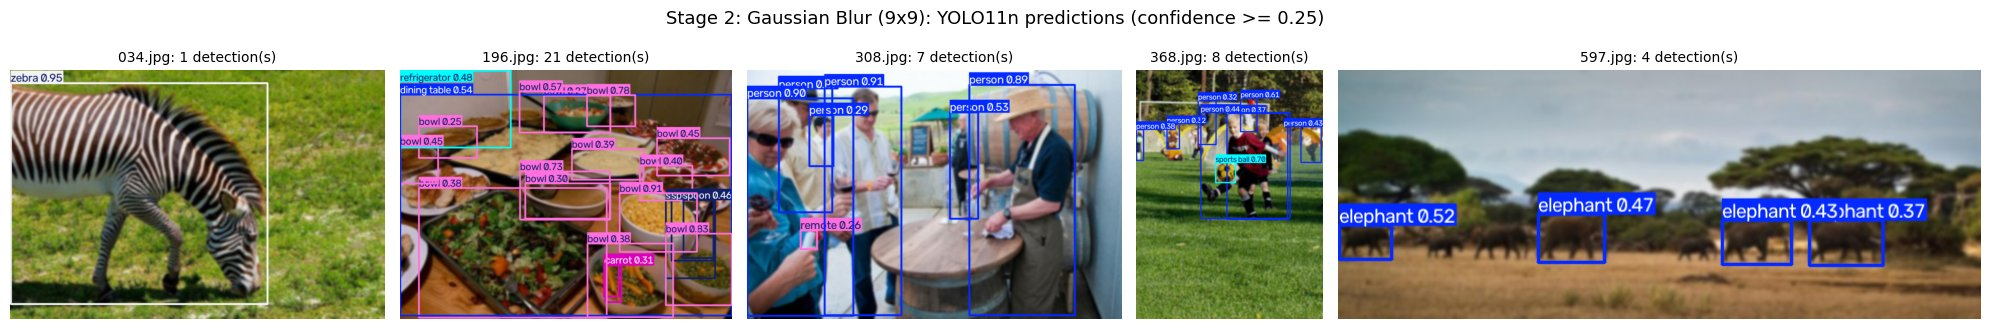

000000000034.jpg: 1 detection(s): 1 zebra [best 0.95]
000000000196.jpg: 21 detection(s): 14 bowl [best 0.91], 3 spoon [best 0.46], 2 carrot [best 0.31], 1 dining table [best 0.54], 1 refrigerator [best 0.48]
000000000308.jpg: 7 detection(s): 6 person [best 0.91], 1 remote [best 0.26]
000000000368.jpg: 8 detection(s): 7 person [best 0.61], 1 sports ball [best 0.70]
000000000597.jpg: 4 detection(s): 4 elephant [best 0.52]
Annotated images saved in: /content/fvl_project/runs/stage2_blurred_predictions


In [5]:

# STAGE 2 — STUDENT CODE

import cv2
import shutil

BLURRED_ROOT = PROJECT_ROOT / 'blurred'

ORIG_IMG_DIR = dataset_dir / 'images' / SPLIT
ORIG_LBL_DIR = dataset_dir / 'labels' / SPLIT


def build_dataset(dst_root, src_img_dir, transform):
    """Apply `transform` to every image in `src_img_dir` and save it under `dst_root`
    with the same filename. The original label files are copied without any change."""
    img_dir = dst_root / 'images' / SPLIT
    lbl_dir = dst_root / 'labels' / SPLIT
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    files = sorted(src_img_dir.glob('*.jpg'))
    for path in files:
        image = cv2.imread(str(path))                          # BGR, uint8
        out = transform(image)
        assert out.shape == image.shape and out.dtype == np.uint8, 'image size / type must not change'
        cv2.imwrite(str(img_dir / path.name), out)             # same filename, OpenCV default JPEG quality (95)
        label = ORIG_LBL_DIR / f'{path.stem}.txt'
        if label.exists():
            shutil.copy2(label, lbl_dir / label.name)          # same labels
    return len(files)


def gaussian_blur(image):
    # 9 x 9 kernel, sigma = 0 -> OpenCV derives sigma from the kernel size: 0.3*((9-1)*0.5 - 1) + 0.8 = 1.7 px
    # (nominal value; the nine sampled kernel taps have a standard deviation of about 1.66 px)
    return cv2.GaussianBlur(image, (9, 9), 0)


# 1-3. Blurred copy of all COCO128 images + labels
n_images = build_dataset(BLURRED_ROOT, ORIG_IMG_DIR, gaussian_blur)
print(f'{n_images} blurred images written to {BLURRED_ROOT / "images" / SPLIT}')

# 4-5. Blurred dataset YAML + validation with the same model and the same settings
STAGE2 = 'Stage 2: Gaussian Blur (9x9)'
metrics_blurred = evaluate(BLURRED_ROOT, 'stage2_blurred')

# 6. The four required metrics
report(STAGE2, metrics_blurred)

# 7. Prediction examples (same five images as Stage 1)
predict_examples(BLURRED_ROOT, 'stage2_blurred', STAGE2)



# Stage 3 — Sharpen the Blurred Images

Apply **one sharpening method** to the Stage 2 blurred images.

You may use a standard sharpening kernel or unsharp masking. Keep the image size unchanged.

### Your task
1. Implement the sharpening operation yourself.
2. Apply it to every blurred image.
3. Save the sharpened images with the same filenames.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector again.
6. Record the same four metrics.
7. Save at least **3 sharpened prediction examples**.

Do not retrain or replace YOLO11n.


Pattern period (px) | contrast kept after blur | after blur + unsharp mask (amount 1.0)
                 32 |                    0.948 | 0.997
                 16 |                    0.807 | 0.963
                  8 |                    0.413 | 0.655
                  4 |                    0.031 | 0.062
128 sharpened images written to /content/fvl_project/sharpened/images/train2017
Ultralytics 8.4.174 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1076.4±313.7 MB/s, size: 57.2 KB)
val: Scanning /content/fvl_project/sharpened/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.6Kit/s 0.1s
val: New cache created: /content/fvl_project/sharpened/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.1s/it 25.0s
             

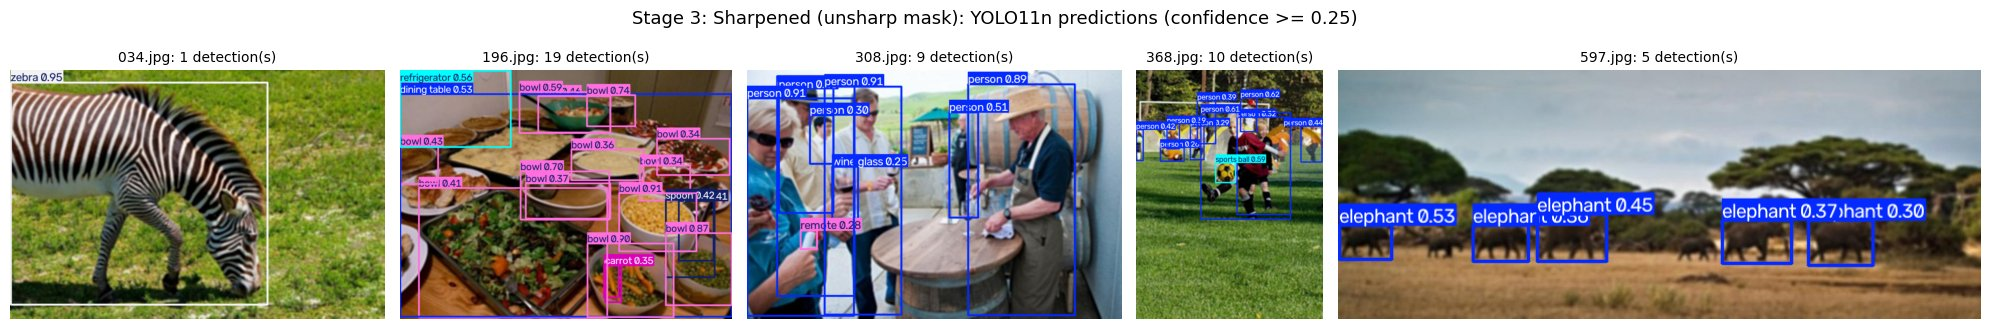

000000000034.jpg: 1 detection(s): 1 zebra [best 0.95]
000000000196.jpg: 19 detection(s): 13 bowl [best 0.91], 2 spoon [best 0.42], 2 carrot [best 0.35], 1 refrigerator [best 0.56], 1 dining table [best 0.53]
000000000308.jpg: 9 detection(s): 7 person [best 0.91], 1 remote [best 0.28], 1 wine glass [best 0.25]
000000000368.jpg: 10 detection(s): 9 person [best 0.62], 1 sports ball [best 0.59]
000000000597.jpg: 5 detection(s): 5 elephant [best 0.53]
Annotated images saved in: /content/fvl_project/runs/stage3_sharpened_predictions


In [6]:

# STAGE 3 — STUDENT CODE

SHARPENED_ROOT = PROJECT_ROOT / 'sharpened'

BLUR_IMG_DIR = BLURRED_ROOT / 'images' / SPLIT


def unsharp_mask(image, ksize=(9, 9), amount=1.0):
    """Unsharp masking, written out step by step:
           low     = GaussianBlur(image)          low-frequency copy of the image
           detail  = image - low                  the edges / fine detail that are still present
           sharp   = image + amount * detail      add the detail back with extra weight
    The arithmetic is done in float32 and the result is clipped to [0, 255], so the image size and type do not change.
    The mask uses the same 9 x 9 Gaussian kernel that produced the blur, with amount = 1."""
    img = image.astype(np.float32)
    low = cv2.GaussianBlur(img, ksize, 0)
    detail = img - low
    sharp = img + amount * detail
    return np.clip(np.rint(sharp), 0, 255).astype(np.uint8)


# Why this can help, in numbers: how much contrast a stripe pattern of a given period keeps
# after the 9 x 9 blur (H), and after blur followed by this unsharp mask, H * (1 + amount * (1 - H)).
kernel_1d = cv2.getGaussianKernel(9, 0).ravel()
taps = np.arange(-4, 5)
print('Pattern period (px) | contrast kept after blur | after blur + unsharp mask (amount 1.0)')
for period in (32, 16, 8, 4):
    H = float(np.sum(kernel_1d * np.cos(2 * np.pi * taps / period)))
    print(f'{period:>19} | {H:>24.3f} | {H * (1 + 1.0 * (1 - H)):.3f}')

# 1-3. Sharpen every blurred image (input = the Stage 2 images, not the originals) + copy labels
n_images = build_dataset(SHARPENED_ROOT, BLUR_IMG_DIR, unsharp_mask)
print(f'{n_images} sharpened images written to {SHARPENED_ROOT / "images" / SPLIT}')

# 4-5. Sharpened dataset YAML + validation with the same model and the same settings
STAGE3 = 'Stage 3: Sharpened (unsharp mask)'
metrics_sharpened = evaluate(SHARPENED_ROOT, 'stage3_sharpened')

# 6. The four required metrics
report(STAGE3, metrics_sharpened)

# 7. Prediction examples (same five images as Stages 1 and 2)
predict_examples(SHARPENED_ROOT, 'stage3_sharpened', STAGE3)


# Supporting checks for the analysis

These cells do not change Stages 1–3. They use the same pretrained YOLO11n (no training) and only add numbers that are quoted in the analysis:

1. **Image sharpness** of each stage, measured as the variance of the Laplacian (more edge detail gives a higher value).
2. **Detections at a fixed confidence of 0.25**, matched to the ground truth (same class, IoU ≥ 0.5) and split by object size using the COCO convention on box area: small < 32², medium 32²–96², large > 96² pixels.
3. **Control and sensitivity runs:** the original images re-saved as JPEG without blur and the blurred images re-saved once more without sharpening (to separate the effect of saving a JPEG again from the effect of the filter), and other sharpening strengths. The Stage 3 result reported in this notebook is only the unsharp mask with amount = 1.0.

In [7]:

# CHECKS 1 and 2: image sharpness and detections at a fixed confidence threshold

def iou_one_to_many(box, boxes):
    x1 = np.maximum(box[0], boxes[:, 0]); y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2]); y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    union = (box[2] - box[0]) * (box[3] - box[1]) + (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]) - inter
    return inter / (union + 1e-9)


def read_ground_truth(stem, w, h):
    """YOLO label file -> class ids and boxes as x1, y1, x2, y2 in pixels."""
    f = ORIG_LBL_DIR / f'{stem}.txt'
    rows = np.loadtxt(f, ndmin=2) if f.exists() and f.stat().st_size > 0 else np.zeros((0, 5))
    cx, cy, bw, bh = rows[:, 1] * w, rows[:, 2] * h, rows[:, 3] * w, rows[:, 4] * h
    return rows[:, 0], np.stack([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], axis=1)


def fixed_threshold_stats(root):
    img_dir = root / 'images' / SPLIT
    names = sorted(p.name for p in img_dir.glob('*.jpg'))
    tp = fp = 0
    found = {'small': 0, 'medium': 0, 'large': 0}
    total = {'small': 0, 'medium': 0, 'large': 0}
    sharpness = []
    for i in range(0, len(names), 16):
        chunk = names[i:i + 16]
        preds = model.predict([str(img_dir / n) for n in chunk], conf=PRED_CONF, imgsz=640,
                              device=DEVICE, verbose=False)
        for name, r in zip(chunk, preds):
            h, w = r.orig_shape
            gt_cls, gt_box = read_ground_truth(name[:-4], w, h)
            matched = np.zeros(len(gt_box), dtype=bool)
            boxes, classes = r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy()
            for j in np.argsort(-r.boxes.conf.cpu().numpy()):          # most confident prediction first
                ious = iou_one_to_many(boxes[j], gt_box)
                ious[(gt_cls != classes[j]) | matched] = 0             # same class, each object matched once
                if len(ious) and ious.max() >= 0.5:
                    matched[ious.argmax()] = True
                    tp += 1
                else:
                    fp += 1
            area = (gt_box[:, 2] - gt_box[:, 0]) * (gt_box[:, 3] - gt_box[:, 1])
            for a, hit in zip(area, matched):
                size = 'small' if a < 32 ** 2 else 'medium' if a < 96 ** 2 else 'large'
                total[size] += 1
                found[size] += int(hit)
            gray = cv2.imread(str(img_dir / name), cv2.IMREAD_GRAYSCALE)
            sharpness.append(cv2.Laplacian(gray, cv2.CV_64F).var())
    n_gt = sum(total.values())
    row = {'Laplacian variance (mean)': round(float(np.mean(sharpness)), 1),
           'Detections': tp + fp, 'Correct (TP)': tp, 'False (FP)': fp, 'Missed objects (FN)': n_gt - tp,
           'Precision @0.25': round(tp / (tp + fp), 4), 'Recall @0.25': round(tp / n_gt, 4)}
    for size in total:
        row[f'Recall {size} (n={total[size]})'] = round(found[size] / total[size], 4)
    return row


stage_roots = {STAGE1: dataset_dir, STAGE2: BLURRED_ROOT, STAGE3: SHARPENED_ROOT}
support_table = pd.DataFrame({stage: fixed_threshold_stats(root) for stage, root in stage_roots.items()}).T
cols_a = ['Laplacian variance (mean)', 'Detections', 'Correct (TP)', 'False (FP)', 'Missed objects (FN)']
display(support_table[cols_a].astype({c: int for c in cols_a[1:]}))
display(support_table.drop(columns=cols_a))


,Laplacian variance (mean),Detections,Correct (TP),False (FP),Missed objects (FN)
Stage 1: Original / Baseline,2747.1,658,485,173,444
Stage 2: Gaussian Blur (9x9),16.0,560,417,143,512
Stage 3: Sharpened (unsharp mask),39.1,577,431,146,498


,Precision @0.25,Recall @0.25,Recall small (n=337),Recall medium (n=281),Recall large (n=311)
Stage 1: Original / Baseline,0.7371,0.5221,0.2077,0.5480,0.8392
Stage 2: Gaussian Blur (9x9),0.7446,0.4489,0.1157,0.4591,0.8006
Stage 3: Sharpened (unsharp mask),0.7470,0.4639,0.1365,0.4804,0.8039


In [8]:

# CHECK 3: control run and sensitivity to the sharpening strength.
# These are extra runs only. The reported Stage 3 result is the unsharp mask with amount = 1.0 (above).

import logging
from ultralytics.utils import LOGGER

EXTRA_ROOT = PROJECT_ROOT / 'extra_checks'

laplacian_kernel = np.array([[0, -1, 0],
                             [-1, 5, -1],
                             [0, -1, 0]], dtype=np.float32)       # standard 3 x 3 sharpening kernel

extra_runs = {
    'Control: original re-saved as JPEG, no blur':        (ORIG_IMG_DIR, lambda im: im),
    'Control: blurred re-saved as JPEG, no sharpening':   (BLUR_IMG_DIR, lambda im: im),
    'Unsharp mask, amount 0.5':                           (BLUR_IMG_DIR, lambda im: unsharp_mask(im, amount=0.5)),
    'Unsharp mask, amount 1.5':                           (BLUR_IMG_DIR, lambda im: unsharp_mask(im, amount=1.5)),
    'Unsharp mask, amount 2.0':                           (BLUR_IMG_DIR, lambda im: unsharp_mask(im, amount=2.0)),
    'Unsharp mask, amount 3.0':                           (BLUR_IMG_DIR, lambda im: unsharp_mask(im, amount=3.0)),
    '3x3 sharpening kernel':                              (BLUR_IMG_DIR, lambda im: cv2.filter2D(im, -1, laplacian_kernel)),
}

rows = {STAGE1: metrics_original, STAGE2: metrics_blurred, STAGE3 + ', amount 1.0': metrics_sharpened}
LOGGER.setLevel(logging.WARNING)                 # hide the validation log of the extra runs, the table below has the numbers
for i, (label, (src_dir, transform)) in enumerate(extra_runs.items()):
    root = EXTRA_ROOT / f'run{i}'
    build_dataset(root, src_dir, transform)
    rows[label] = evaluate(root, f'extra_run{i}')
LOGGER.setLevel(logging.INFO)

extra_table = pd.DataFrame(rows).T
display(extra_table.round(4))


,Precision,Recall,mAP@0.5,mAP@0.5:0.95
Stage 1: Original / Baseline,0.6633,0.5894,0.6696,0.5024
Stage 2: Gaussian Blur (9x9),0.6784,0.5351,0.6168,0.4434
"Stage 3: Sharpened (unsharp mask), amount 1.0",0.6192,0.5652,0.6296,0.4561
"Control: original re-saved as JPEG, no blur",0.6535,0.5831,0.6700,0.5020
"Control: blurred re-saved as JPEG, no sharpening",0.6542,0.5461,0.6135,0.4418
"Unsharp mask, amount 0.5",0.6889,0.5275,0.6207,0.4494
"Unsharp mask, amount 1.5",0.6281,0.5663,0.6324,0.4626
"Unsharp mask, amount 2.0",0.6677,0.5379,0.6178,0.4470
"Unsharp mask, amount 3.0",0.6088,0.5473,0.6051,0.4427
3x3 sharpening kernel,0.6583,0.5468,0.6275,0.4555


# Stage 4 — Results table and side-by-side examples (code)

                                   Precision  Recall  mAP@0.5  mAP@0.5:0.95
Stage 1: Original / Baseline          0.6633  0.5894   0.6696        0.5024
Stage 2: Gaussian Blur (9x9)          0.6784  0.5351   0.6168        0.4434
Stage 3: Sharpened (unsharp mask)     0.6192  0.5652   0.6296        0.4561

Change in each metric
                       Precision  Recall  mAP@0.5  mAP@0.5:0.95
Blur vs Baseline         +0.0151 -0.0543  -0.0528       -0.0590
Sharpened vs Blur        -0.0592 +0.0301  +0.0128       +0.0127
Sharpened vs Baseline    -0.0441 -0.0242  -0.0400       -0.0463


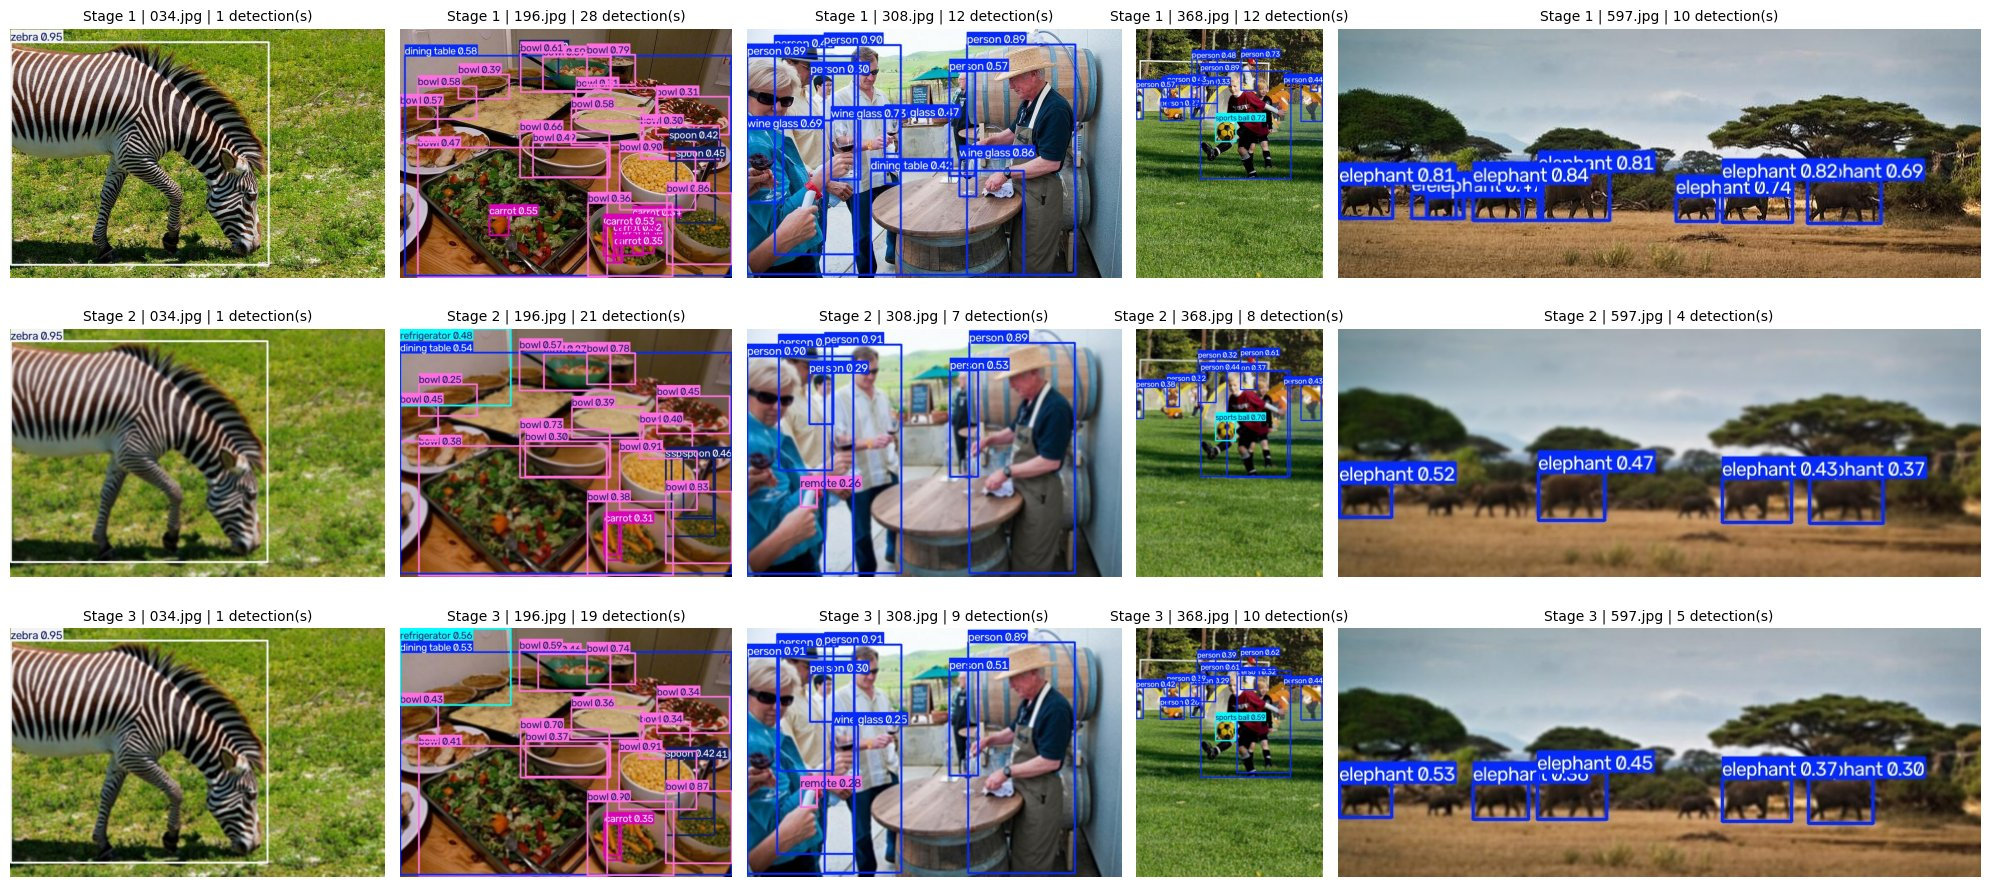

In [9]:

# STAGE 4: final table (values printed to 4 decimal places) and a side-by-side view of the examples

final_table = pd.DataFrame(final_results).T.round(4)
print(final_table.to_string(float_format=lambda v: f'{v:.4f}'))

change = pd.DataFrame({
    'Blur vs Baseline':      final_table.loc[STAGE2] - final_table.loc[STAGE1],
    'Sharpened vs Blur':     final_table.loc[STAGE3] - final_table.loc[STAGE2],
    'Sharpened vs Baseline': final_table.loc[STAGE3] - final_table.loc[STAGE1],
}).T
print('\nChange in each metric')
print(change.to_string(float_format=lambda v: f'{v:+.4f}'))

# Same five images, one row per stage, read back from the saved prediction folders
stage_tags = {STAGE1: 'stage1_original', STAGE2: 'stage2_blurred', STAGE3: 'stage3_sharpened'}
saved = {stage: [cv2.imread(str(RUNS_DIR / f'{tag}_predictions' / name)) for name in EXAMPLE_IMAGES]
         for stage, tag in stage_tags.items()}
ratios = [im.shape[1] / im.shape[0] for im in saved[STAGE1]]
fig, axes = plt.subplots(3, len(EXAMPLE_IMAGES), figsize=(20, 3 * (20 / sum(ratios) + 0.5)),
                         gridspec_kw={'width_ratios': ratios})
for row, stage in zip(axes, stage_tags):
    for ax, name, im in zip(row, EXAMPLE_IMAGES, saved[stage]):
        ax.imshow(im[..., ::-1])
        ax.set_title(f'{stage.split(":")[0]} | {name[-7:]} | {len(example_log[stage][name])} detection(s)', fontsize=10)
        ax.axis('off')
fig.tight_layout()
fig.savefig(FIG_DIR / f'{ROLL}_all_stages_comparison.png', dpi=120, bbox_inches='tight')
plt.show()



# Stage 4 — Final Results - 10 Marks (Code, Results, Prediction Examples)

Enter your final values in the table below and the **values must be upto 4 decimal points.**

| Stage | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---:|---:|---:|---:|
| Original / Baseline | 0.6633 | 0.5894 | 0.6696 | 0.5024 |
| Gaussian Blur | 0.6784 | 0.5351 | 0.6168 | 0.4434 |
| Sharpened | 0.6192 | 0.5652 | 0.6296 | 0.4561 |

All three stages use the same pretrained YOLO11n and the same validation settings (image size 640, batch 16, confidence 0.001, NMS IoU 0.7) on the 128 COCO128 images (929 labelled objects). The values are copied from the executed cells above (CPU run); on a GPU the last decimals can differ slightly. COCO128 is taken from the COCO training set, so the baseline is optimistic, but the comparison is fair because all three stages use the same images. Prediction examples for every stage are shown under Stages 1–3 and side by side in the cell above. Image numbers below (034, 196, 308, 368, 597) are the last digits of the file names.

## Analysis — 10 Marks (in points, Max 4 points for each)

### A. Effect of blur — 3 marks
What changed from Stage 1 to Stage 2? Use your actual metric values and prediction examples.

1. **Recall and mAP fell, precision did not.** Recall dropped from 0.5894 to 0.5351 (−0.0543), mAP@0.5 from 0.6696 to 0.6168 (−0.0528, about −7.9%) and mAP@0.5:0.95 from 0.5024 to 0.4434 (−0.0590, about −11.7%). Precision did not fall at all; it rose slightly (0.6633 → 0.6784). So blur makes the detector miss objects rather than invent them. The stricter metric lost more, which shows that the boxes that remain are also placed less accurately.
2. **Cause.** The 9×9 Gaussian (nominal σ = 1.7 px) is a low-pass filter that removes edges and texture. The mean Laplacian variance of the images fell from 2747.1 to 16.0, and a pattern with an 8-pixel period keeps only 0.413 of its contrast (4-pixel period: 0.031). YOLO11n was trained mostly on sharp COCO images, so blurred inputs are a distribution shift and its confidence scores fall. Re-saving the originals as JPEG without blur leaves mAP@0.5:0.95 at 0.5020, so the loss comes from the blur and not from re-saving the files.
3. **Small objects are hit hardest.** At a fixed confidence of 0.25 the detections fell from 658 to 560 and the correct ones from 485 to 417. Recall fell from 0.2077 to 0.1157 for small objects (about −44%), from 0.5480 to 0.4591 for medium (about −16%) and only from 0.8392 to 0.8006 for large (about −5%). A small object is only a few pixels wide, so a 9-pixel kernel mixes it with the background.
4. **Examples.** The large zebra (034) keeps its confidence of 0.95. In 597 the elephant boxes fall from 10 to 4 and the best confidence from 0.84 to 0.52. In 308 all 5 wine-glass boxes disappear and a wrong "remote" box appears. In 368 the persons found fall from 11 to 7, the small ones in the background are lost. In the crowded image 196 the detections fall from 28 to 21 and a wrong "refrigerator" box appears.

### B. Why sharpening? — 2 marks
What sharpening method did you use, and why can it help after blur?

1. **Method.** Unsharp masking, written by hand in NumPy: `sharp = I + amount × (I − GaussianBlur(I))`, with the same 9×9 Gaussian as the blur and amount = 1.0. It is applied to the Stage 2 images in float32, then rounded and clipped to [0, 255], so the image size and the labels do not change.
2. **Why it can help.** Blur weakens the middle and high frequencies, which carry the edges. `I − GaussianBlur(I)` is the edge detail that survived, and adding it back raises the edge contrast. With the same Gaussian, the contrast H left by the blur becomes H(2 − H): 0.807 → 0.963 for a 16-pixel pattern and 0.413 → 0.655 for an 8-pixel pattern (printed in Stage 3). The image moves back towards the sharp images the detector was trained on.
3. **Choice of amount.** This formula is one step of Van Cittert deconvolution, and amount = 1 is the largest value for which the combined gain never goes above 1 at any frequency, so edges are not overshot. The amount was set from this argument and not by taking the best score: in the sensitivity check amount 1.5 scores slightly higher (0.4626) and I still report 1.0.
4. **Limit.** It can only amplify what is still in the image. A 4-pixel pattern goes from 0.031 to 0.062, so the finest detail stays lost, and noise and JPEG artefacts are amplified together with the edges.

### C. Did sharpening help? — 4 marks
Compare Stage 2 and Stage 3. What improved? What did not improve? Did any metric become worse? Use your actual values and examples.

1. **What improved.** Recall rose from 0.5351 to 0.5652 (+0.0301), mAP@0.5 from 0.6168 to 0.6296 (+0.0128) and mAP@0.5:0.95 from 0.4434 to 0.4561 (+0.0127). Re-saving the blurred images once more without sharpening gives 0.4418 against 0.4434 for Stage 2, so the gain comes from the filter and not from saving the JPEG again. It is real but small. At confidence 0.25 the correct detections rose from 417 to 431 and small-object recall from 0.1157 to 0.1365. In 368 two background persons come back (7 → 9), in 597 a fifth elephant is found and in 308 one wine glass returns.
2. **What became worse.** Precision fell from 0.6784 to 0.6192 (−0.0592), below even the baseline (0.6633). Ultralytics reports P and R at the confidence with the best F1, so the recall gain is partly a shift of this operating point: F1 computed from P and R is almost the same (0.598 → 0.591), and at a fixed confidence of 0.25 precision does not change (0.7446 → 0.7470). Sharpening also strengthens wrong detections: in 196 the "refrigerator" box rises from 0.48 to 0.56 while the detections fall from 21 to 19, and the "remote" box in 308 stays (0.26 → 0.28).
3. **What did not improve.** Only about a quarter of the loss came back (about 24% of mAP@0.5 and 22% of mAP@0.5:0.95). Stage 3 is still 0.0400 and 0.0463 below the baseline. Small-object recall is 0.1365 against 0.2077 for the originals, and the Laplacian variance is 39.1 against 2747.1. In 308 only 1 of the 5 wine-glass boxes returns (confidence 0.25) and 597 has 5 elephant boxes instead of 10. Large objects did not need help (0.8006 → 0.8039).
4. **It is not a tuning problem.** With amounts from 0.5 to 3.0, mAP@0.5:0.95 stays between 0.4427 and 0.4626, and a 3×3 sharpening kernel gives 0.4555. Nothing comes close to 0.5024. Amount 3.0 (0.4427) is even below the blurred images (0.4434), because over-sharpening adds halos and noise. The detail was removed by the blur, not hidden, so a linear filter cannot bring it back.

### D. Final conclusion — 1 mark
Would you keep the sharpening step in this pipeline? Explain in no more than 100 words.

I would not keep sharpening as a fixed step in this pipeline. On the blurred images it gave a small gain (mAP@0.5:0.95 0.4434 → 0.4561, about 22% of what the blur removed), but precision fell from 0.6784 to 0.6192 and small objects stayed lost, because unsharp masking only amplifies the detail that survived. I would use it only as a cheap optional step when the input is known to be blurred and recall matters more than precision. A better solution is to avoid the blur, or to train the detector with blur augmentation.


# Submission

Submit:
1. Completed `.ipynb` with final results table and with at least 3 prediction examples from each stage: Original, Blurred, Sharpened
2. Google Form for Results, Prediction examples and Analysis submission

Use your roll number in every submitted filename.
Students are requested to submit in time 1 marks will be deducted per day for late submission

Deadline: Sun, 25 October 2026, 11:59 P.M.
